# 14-loyiha
Subguruhlar bo‘yicha baholash va psevdonimlashtirish

fairness_audit.csv: sun’iy guruhlar va oldindan yaratilgan ballar. HMAC psevdonimlashtirish anonimlashtirish kafolati emas.


In [1]:
# Subguruhlar bo‘yicha baholash va psevdonimlashtirish
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

ROOT = (Path(__file__).resolve().parent
        if "__file__" in globals() else Path.cwd())
DATA, OUT = ROOT / "data", ROOT / "outputs"
DATA.mkdir(exist_ok=True)
OUT.mkdir(exist_ok=True)
SEED = 42

def save_json(name, value):
    text = json.dumps(value, indent=2, ensure_ascii=False,
                      allow_nan=False, default=str)
    (OUT / name).write_text(text, encoding="utf-8")

def save_plot(name):
    plt.tight_layout()
    plt.savefig(OUT / name, dpi=140)
    plt.close()

from sklearn.metrics import (accuracy_score, precision_score,
    recall_score, f1_score, roc_auc_score, confusion_matrix,
    brier_score_loss, ConfusionMatrixDisplay)

def binary_metrics(y, probability, threshold=0.5):
    pred = np.asarray(probability) >= threshold
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return dict(n=int(len(y)), threshold=float(threshold),
        accuracy=float(accuracy_score(y, pred)),
        precision=float(precision_score(y, pred, zero_division=0)),
        recall=float(recall_score(y, pred, zero_division=0)),
        specificity=float(tn / (tn + fp)) if tn + fp else None,
        f1=float(f1_score(y, pred, zero_division=0)),
        roc_auc=float(roc_auc_score(y, probability))
            if len(np.unique(y)) == 2 else None,
        brier=float(brier_score_loss(y, probability)),
        tn=int(tn), fp=int(fp), fn=int(fn), tp=int(tp))

import os
import hmac
import hashlib
from math import sqrt

def wilson(success, total):
    if total == 0:
        return None, None
    z, p = 1.96, success / total
    centre = (p + z*z/(2*total)) / (1 + z*z/total)
    half = z * sqrt(p*(1-p)/total + z*z/(4*total*total))
    half /= 1 + z*z/total
    return centre - half, centre + half

def main():
    path = DATA / "fairness_audit.csv"
    if not path.exists():
        rng = np.random.default_rng(SEED)
        n = 700
        group = rng.choice(["A", "B"], n, p=[.7, .3])
        truth = rng.binomial(1, .35, n)
        score = .2 + truth * .55 - (group == "B") * .2
        score = np.clip(score + rng.normal(0, .17, n), 0, 1)
        pd.DataFrame({"patient_id": [f"SYN{i}" for i in range(n)],
            "sex_group": group, "age_group": rng.choice(
                ["younger", "older"], n), "y_true": truth,
            "probability": score}).to_csv(path, index=False)
    df = pd.read_csv(path)
    if not df.probability.between(0, 1).all():
        raise ValueError("Ehtimollik [0,1] oralig‘ida bo‘lishi kerak")
    rows = []
    for field in ["sex_group", "age_group"]:
        for group, sub in df.groupby(field):
            metrics = binary_metrics(sub.y_true, sub.probability)
            lo, hi = wilson(metrics["tp"], metrics["tp"] + metrics["fn"])
            rows.append({"field": field, "group": group,
                "prevalence": float(sub.y_true.mean()),
                "positive_rate": float((sub.probability >= .5).mean()),
                "recall_ci_low": lo, "recall_ci_high": hi,
                "fpr": 1 - metrics["specificity"]
                    if metrics["specificity"] is not None else None,
                **metrics})
    audit = pd.DataFrame(rows)
    audit.to_csv(OUT / "subgroup_metrics.csv", index=False)
    gaps = audit.groupby("field").agg(
        recall_gap=("recall", lambda s: s.max()-s.min()),
        positive_rate_gap=("positive_rate", lambda s: s.max()-s.min()))
    gaps.to_csv(OUT / "fairness_gaps.csv")
    sex = audit[audit.field == "sex_group"].set_index("group")
    sex[["recall", "precision", "positive_rate"]].plot.bar(ylim=(0, 1))
    plt.title("Sun’iy guruhlar: yagona 0.5 threshold")
    save_plot("group_comparison.png")
    key = os.environ.get("TSI_PSEUDONYM_KEY")
    key_bytes = key.encode() if key else os.urandom(32)
    token = df.patient_id.map(lambda value: hmac.new(key_bytes,
        str(value).encode(), hashlib.sha256).hexdigest())
    minimal = df[["sex_group", "age_group", "y_true", "probability"]].copy()
    minimal.insert(0, "study_token", token)
    minimal.to_csv(OUT / "minimal_pseudonymized.csv", index=False)
    save_json("summary.json", {"source": "synthetic", "rows": len(df),
        "identifier_removed_from_export": "patient_id" not in minimal,
        "key_stored": False, "anonymization_claimed": False})
    (OUT / "privacy_notes.md").write_text(
        "# Maxfiylik va talqin\n\n"
        "Kalit eksport qilinmaydi. Yangi kalit tokenlarni o‘zgartiradi.\n"
        "Guruh va kam uchraydigan belgilar qayta aniqlash xavfini saqlaydi.\n"
        "Kichik guruhlar noaniqlik bilan talqin qilinadi.\n"
        "Thresholdni test yoki guruh natijasiga qarab o‘zgartirmang.\n"
        "Yumshatish chorasi yangi validatsiyada tekshirilishi kerak.\n",
        encoding="utf-8")
    print(audit[["field", "group", "n", "recall", "precision"]].to_string(
        index=False))

if __name__ == "__main__":
    main()


    field   group   n   recall  precision
sex_group       A 486 0.900621   0.941558
sex_group       B 214 0.600000   1.000000
age_group   older 335 0.789916   0.940000
age_group younger 365 0.811475   0.970588


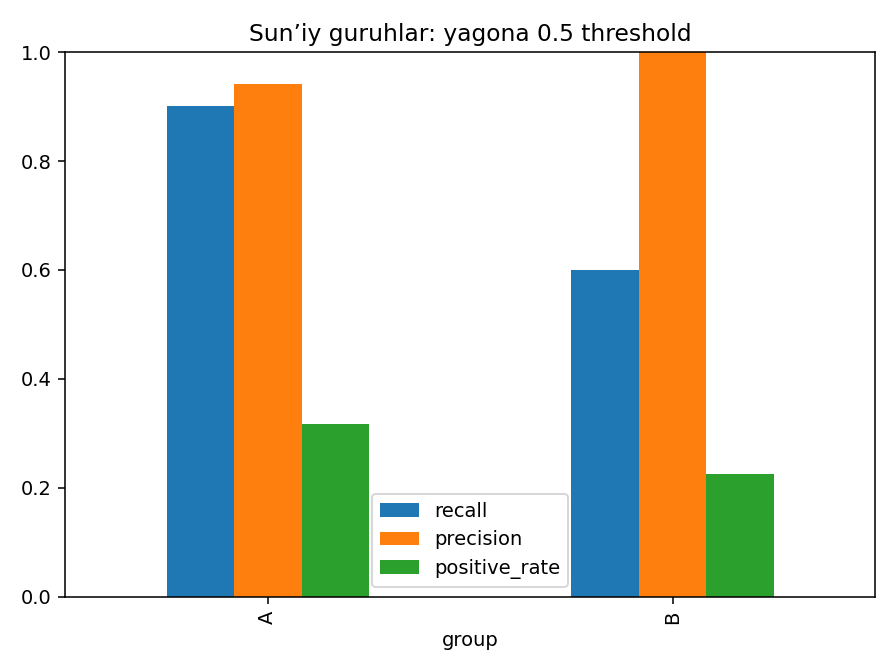

In [2]:
from IPython.display import display, Image
for path in sorted(OUT.glob("*.png")):
    display(Image(filename=str(path)))
